# KNN – Customer Value Prediction

## Introduction
K-Nearest Neighbors (KNN) labels a customer by looking at the **K most similar customers** in the training data and taking a **majority vote**.

## How it works (simple idea)
- Find the K closest customers (by distance).
- Count how many of them are High-Value.
- The majority decides. We use **K = 15**, chosen with cross-validation (shown below).
- Because it uses distance, **scaling is required**.

## Step 1: Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# The CSV is one folder up. If you move the notebook, it also checks the current folder.
data_path = Path("../marketing_campaign.csv")
if not data_path.exists():
    data_path = Path("marketing_campaign.csv")

df = pd.read_csv(data_path)
print("Shape:", df.shape)
df.head()

Shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


## Step 2: Check the data

In [2]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nRepeated customers (same data, different ID):", df.drop("ID", axis=1).duplicated().sum())

Missing values:
Income    24
dtype: int64

Repeated customers (same data, different ID): 182


## Data Preprocessing
1. **Remove repeated customers** – same data entered twice with a new ID.
2. **Create the target** `total_spending` = money spent on wine, fruit, meat, fish, sweets and gold.
3. **Create age** from year of birth (data collected in 2014).
4. **Keep the useful columns** and give them short names.
5. **Remove rows with missing income** (only 24 rows).
6. **Remove impossible values** – age above 90 and one income of 666,666.
7. **Fix strange marital status values** ("Alone", "Absurd", "YOLO" → "Single").

In [3]:
df = df.drop("ID", axis=1).drop_duplicates()

spending_columns = ["MntWines", "MntFruits", "MntMeatProducts",
                    "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["total_spending"] = df[spending_columns].sum(axis=1)
df["age"] = 2014 - df["Year_Birth"]

df = df[["age", "Education", "Marital_Status", "Income", "Kidhome",
         "Teenhome", "Recency", "NumWebVisitsMonth", "total_spending"]]
df.columns = ["age", "education", "marital_status", "income", "kids",
              "teens", "recency", "web_visits", "total_spending"]

df = df.dropna()
df = df[(df["age"] <= 90) & (df["income"] <= 200000)]
df["marital_status"] = df["marital_status"].replace(
    {"Alone": "Single", "Absurd": "Single", "YOLO": "Single"}
)

print("Shape after cleaning:", df.shape)
df.head()

Shape after cleaning: (2030, 9)


,age,education,marital_status,income,kids,teens,recency,web_visits,total_spending
0,57,Graduation,Single,58138.0,0,0,58,7,1617
1,60,Graduation,Single,46344.0,1,1,38,5,27
2,49,Graduation,Together,71613.0,0,0,26,4,776
3,30,Graduation,Together,26646.0,1,0,26,6,53
4,33,PhD,Married,58293.0,1,0,94,5,422


## Creating the Target (High-Value or Regular customer)
The company wants to know which customers are worth targeting with a loyalty offer.
- **1 = High-Value Customer** → spent **400 or more** in two years
- **0 = Regular Customer** → spent less than 400

400 is close to the median spending (397), so the two groups are almost the same size. It is a fixed business rule, so no information from the test data is used to create it.

In [4]:
df["high_value"] = (df["total_spending"] >= 400).astype(int)

print("Customers in each class:")
print(df["high_value"].value_counts())

Customers in each class:
high_value
0    1017
1    1013
Name: count, dtype: int64


## Encoding text columns
Models only understand numbers. `get_dummies` turns **education** and **marital_status** into 0/1 columns
(one-hot encoding). `drop_first=True` removes one column from each group because it can be worked out from the others.

In [5]:
X = df.drop(["total_spending", "high_value"], axis=1)
X = pd.get_dummies(X, drop_first=True, dtype=int)
y = df["high_value"]

print("Input columns:", list(X.columns))
print("X shape:", X.shape)

Input columns: ['age', 'income', 'kids', 'teens', 'recency', 'web_visits', 'education_Basic', 'education_Graduation', 'education_Master', 'education_PhD', 'marital_status_Married', 'marital_status_Single', 'marital_status_Together', 'marital_status_Widow']
X shape: (2030, 14)


## Train-Test Split
- **80% training data** → the model learns from this.
- **20% testing data** → kept hidden and used to check the model honestly.
- `random_state=42` → same split every time.
- `stratify=y` → same High/Regular balance in both parts.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers :", len(X_test))

Training customers: 1624
Testing customers : 406


## Feature Scaling
Income is in the thousands, while kids is only 0 to 2. This model uses **distances or weights**, so the big income
numbers would dominate. `StandardScaler` puts every column on the same scale (mean 0, standard deviation 1).

The scaler is **fitted on training data only**, then used to transform the test data, so no test information leaks into training.

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("First scaled training row:", X_train[0].round(2))

First scaled training row: [ 1.09  0.72 -0.84  0.88  0.8   0.26 -0.15  1.   -0.45 -0.53  1.25 -0.53
 -0.57 -0.2 ]


## Train the KNN model

In [8]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train, y_train)

print("Model trained!")

Model trained!


## Make predictions on the test data

In [9]:
y_pred = model.predict(X_test)

print("Actual   :", list(y_test[:15]))
print("Predicted:", list(y_pred[:15]))

Actual   : [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1]
Predicted: [np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(1)]


## Evaluate the model

In [10]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")
print()
print(classification_report(y_test, y_pred, target_names=["Regular", "High-Value"]))

Accuracy : 85.71 %
Precision: 82.22 %
Recall   : 91.13 %
F1-Score : 86.45 %

              precision    recall  f1-score   support

     Regular       0.90      0.80      0.85       203
  High-Value       0.82      0.91      0.86       203

    accuracy                           0.86       406
   macro avg       0.86      0.86      0.86       406
weighted avg       0.86      0.86      0.86       406



| Metric | Easy meaning (business view) |
|---|---|
| **Accuracy** | Out of all test customers, how many were labelled correctly? |
| **Precision** | When the model says "High-Value", how often is it right? (avoids wasting offers) |
| **Recall** | Out of all real High-Value customers, how many did the model find? (avoids missing good customers) |
| **F1-Score** | One number that balances Precision and Recall. |

For all of them: **higher is better**.

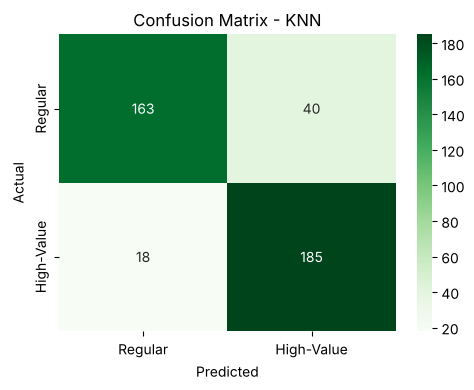

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Regular", "High-Value"], yticklabels=["Regular", "High-Value"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN")
plt.tight_layout()
plt.show()

**How to read the confusion matrix**
- Top-left: Regular customers correctly predicted as Regular
- Bottom-right: High-Value customers correctly predicted as High-Value
- Top-right: Regular customers wrongly called High-Value (a wasted offer)
- Bottom-left: High-Value customers the model missed (a lost opportunity)

## Choosing K with cross-validation (training data only)

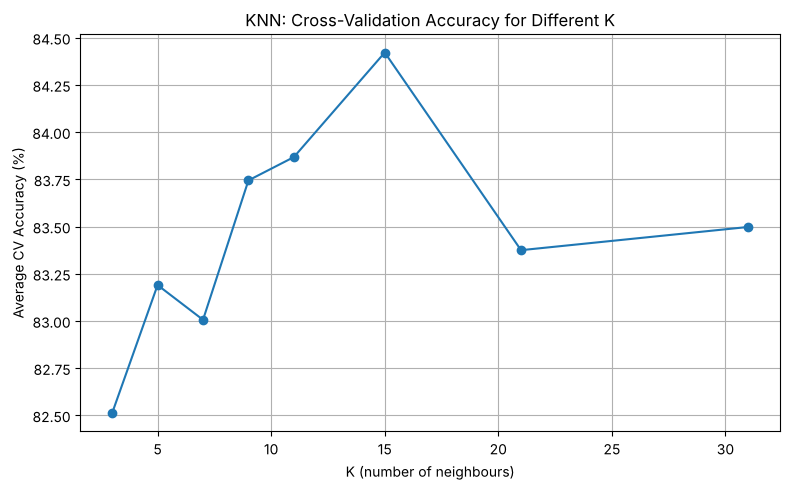

K = 3 -> 82.51 %
K = 5 -> 83.19 %
K = 7 -> 83.01 %
K = 9 -> 83.74 %
K = 11 -> 83.87 %
K = 15 -> 84.42 %
K = 21 -> 83.37 %
K = 31 -> 83.5 %


In [12]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

# Use the unscaled training data. The pipeline scales inside each fold, so nothing leaks.
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [3, 5, 7, 9, 11, 15, 21, 31]
scores = []

for k in k_values:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores.append(cross_val_score(knn, X_tr, y_tr, cv=folds).mean() * 100)

plt.figure(figsize=(8, 5))
plt.plot(k_values, scores, marker="o")
plt.title("KNN: Cross-Validation Accuracy for Different K")
plt.xlabel("K (number of neighbours)")
plt.ylabel("Average CV Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

for k, s in zip(k_values, scores):
    print("K =", k, "->", round(s, 2), "%")

K = 15 has the highest average cross-validation accuracy, so it is used in the final model. Very small K (3) is the worst because one or two odd neighbours can change the answer.

## Interpretation
- KNN got **85.71% accuracy**, the **lowest** of all models.
- **Why?** KNN treats every column as equally important. The 8 one-hot education/marital columns count as much as income in the distance, even though income matters far more. This adds noise to the "nearest neighbours".
- Cross-validation on the training data gave the best result at **K = 15** (84.42%), about 1% better than the usual default K = 5. Larger K means a bigger vote, which is less affected by a few unusual neighbours.

In [13]:
print("KNN SUMMARY")
print("-" * 30)
print("Dataset       : Customer Personality Analysis (iFood)")
print("Task          : Classification (High-Value / Regular)")
print("Train records :", len(X_train))
print("Test records  :", len(X_test))
print("Accuracy      :", round(accuracy * 100, 2), "%")
print("F1-Score      :", round(f1 * 100, 2), "%")

KNN SUMMARY
------------------------------
Dataset       : Customer Personality Analysis (iFood)
Task          : Classification (High-Value / Regular)
Train records : 1624
Test records  : 406
Accuracy      : 85.71 %
F1-Score      : 86.45 %
